# 09. Fixed-model comparison on Lab Test and Field Dev

This notebook evaluates four already-trained checkpoints: the two laboratory baselines, mixed ResNet18 initialized from the geometric-augmentation checkpoint, and mixed ViT-Small. It compares accuracy, macro-F1, class-level recall, and paired field errors without updating weights or selecting checkpoints.

Lab Test contains 1,692 PlantVillage images. Field Dev contains 92 PlantDoc images and previously selected the mixed checkpoints; its metrics remain development results. The original 47-image Field Test was inspected in earlier baseline analysis and is not evaluated here. Independent field confirmation is unavailable.

## Runtime and artifacts

The saved evaluation uses CPU and source revision `70836c29f770cab3473d02e6cff7385cdeef6bd4`. The Colab setup mounts Drive and locates the required checkpoints. Execution performs inference and writes to `final_comparison_development/`; viewing saved outputs requires neither checkpoint access nor inference.

In [1]:
%pip install -q "timm==1.0.26" datasets pandas scikit-learn matplotlib pillow

In [2]:
from pathlib import Path
import gc
import hashlib
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
import torch
from google.colab import drive
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)
from torch import nn
from torch.utils.data import DataLoader
from torchvision.models import ResNet18_Weights, resnet18

REPO_URL = "https://github.com/thutrang147/plant-disease-diagnosis.git"
PROJECT_ROOT = Path("/content/plant-disease-diagnosis")
if PROJECT_ROOT.exists():
    subprocess.run(["git", "-C", str(PROJECT_ROOT), "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_ROOT)], check=True)
GIT_SHA = subprocess.check_output(
    ["git", "-C", str(PROJECT_ROOT), "rev-parse", "HEAD"], text=True
).strip()
sys.path.insert(0, str(PROJECT_ROOT))
from src.dataset import PlantDiseaseDataset

drive.mount("/content/drive")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SPLITS_DIR = PROJECT_ROOT / "data" / "splits"
DRIVE_ROOT = Path("/content/drive/MyDrive/plant-disease-diagnosis")
OUTPUT_ROOT = DRIVE_ROOT / "final_comparison_development"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("Repository commit:", GIT_SHA)
print("Evaluation device:", DEVICE)
print("Output directory:", OUTPUT_ROOT)

Mounted at /content/drive
Repository commit: 70836c29f770cab3473d02e6cff7385cdeef6bd4
Evaluation device: cpu
Output directory: /content/drive/MyDrive/plant-disease-diagnosis/final_comparison_development


## Checkpoint and partition provenance

All four models use identical Lab Test and Field Dev manifests and the shared five-class mapping. Mixed checkpoints must match the Field Dev hash, Lab Validation hash, and source checkpoint hash. The original Field Test manifest is read for integrity checks, without loading its images for model inference.

In [3]:
def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

LABEL_MAP = json.loads((SPLITS_DIR / "label_map.json").read_text(encoding="utf-8"))
CLASS_NAMES = [name for name, idx in sorted(LABEL_MAP.items(), key=lambda item: item[1])]
LABEL_IDS = list(range(5))
assert sorted(LABEL_MAP.values()) == LABEL_IDS and len(CLASS_NAMES) == 5

MANIFESTS = {
    name: SPLITS_DIR / f"{name}.csv"
    for name in ("lab_test", "lab_val", "field_dev", "field_adapt_train", "field_test")
}
for name, path in MANIFESTS.items():
    assert path.is_file(), f"Missing {name} manifest: {path}. Push the verified manifests to GitHub."
frames = {name: pd.read_csv(path) for name, path in MANIFESTS.items()}
assert len(frames["lab_test"]) == 1692
assert len(frames["field_dev"]) == 92
assert len(frames["field_adapt_train"]) == 370
assert len(frames["field_test"]) == 47
assert len(frames["lab_val"]) == 1341

for name, frame in frames.items():
    assert frame["row_id"].is_unique, f"Repeated source row_id: {name}"
    assert (frame["class_name"].map(LABEL_MAP) == frame["label_id"]).all(), name
    expected_source = "plantvillage" if name.startswith("lab_") else "plantdoc"
    assert (frame["source"] == expected_source).all(), name

# A manifest-level check; original image-content audit was completed in Steps 6–8.
assert set(frames["field_adapt_train"].row_id).isdisjoint(set(frames["field_dev"].row_id))
assert set(frames["field_adapt_train"].row_id).isdisjoint(set(frames["field_test"].row_id))
assert set(frames["field_dev"].row_id).isdisjoint(set(frames["field_test"].row_id))
assert set(frames["lab_val"].row_id).isdisjoint(set(frames["lab_test"].row_id))
for a, b in (("field_adapt_train", "field_dev"), ("field_adapt_train", "field_test"), ("field_dev", "field_test")):
    if "group_id" in frames[a].columns and "group_id" in frames[b].columns:
        assert set(frames[a].group_id).isdisjoint(set(frames[b].group_id)), (a, b)

MANIFEST_HASHES = {name: sha256_file(path) for name, path in MANIFESTS.items()}
print("Class order:", CLASS_NAMES)
print("Lab Test:", len(frames["lab_test"]), "Field Dev:", len(frames["field_dev"]))
print("Field Dev SHA256:", MANIFEST_HASHES["field_dev"])
print("Field Test is present but is NOT evaluated in this notebook.")
display(pd.crosstab(
    pd.concat([
        frames["lab_test"].assign(partition="Lab Test"),
        frames["field_dev"].assign(partition="Field Dev"),
    ], ignore_index=True)["class_name"],
    pd.concat([
        frames["lab_test"].assign(partition="Lab Test"),
        frames["field_dev"].assign(partition="Field Dev"),
    ], ignore_index=True)["partition"],
))

Class order: ['Healthy', 'Early Blight', 'Late Blight', 'Bacterial Spot', 'Septoria Leaf Spot']
Lab Test: 1692 Field Dev: 92
Field Dev SHA256: 2c61790f90214b3a4bbeb5e7f3e6228e6f2c013cab3cfe0b320a28a6aae960e9
Field Test is present but is NOT evaluated in this notebook.


partition,Field Dev,Lab Test
class_name,,
Bacterial Spot,18,424
Early Blight,16,200
Healthy,11,326
Late Blight,20,382
Septoria Leaf Spot,27,360


In [4]:
CHECKPOINT_SPECS = {
    "ResNet18 · Lab baseline": {
        "architecture": "resnet18", "checkpoint": DRIVE_ROOT / "resnet18_baseline/resnet18_lab_best.pt",
        "source_checkpoint": DRIVE_ROOT / "resnet18_baseline/resnet18_lab_best.pt", "batch_size": 32,
        "phase": "lab_only",
    },
    "ViT-Small · Lab baseline": {
        "architecture": "vit_small_patch16_224.augreg_in1k",
        "checkpoint": DRIVE_ROOT / "vit_small_baseline/vit_small_lab_best.pt",
        "source_checkpoint": DRIVE_ROOT / "vit_small_baseline/vit_small_lab_best.pt", "batch_size": 16,
        "phase": "lab_only",
    },
    "ResNet18 · Geometric + Mixed": {
        "architecture": "resnet18",
        "checkpoint": DRIVE_ROOT / "mixed_domain_verified/R2_resnet_geometric/mixed_domain_best.pt",
        "source_checkpoint": DRIVE_ROOT / "resnet18_aug_geometric/resnet18_best.pt", "batch_size": 32,
        "phase": "mixed_domain",
    },
    "ViT-Small · Mixed": {
        "architecture": "vit_small_patch16_224.augreg_in1k",
        "checkpoint": DRIVE_ROOT / "mixed_domain_verified/V1_vit_small/mixed_domain_best.pt",
        "source_checkpoint": DRIVE_ROOT / "vit_small_baseline/vit_small_lab_best.pt", "batch_size": 16,
        "phase": "mixed_domain",
    },
}

for name, spec in CHECKPOINT_SPECS.items():
    assert spec["checkpoint"].is_file(), f"Missing checkpoint for {name}: {spec['checkpoint']}"
    assert spec["source_checkpoint"].is_file(), f"Missing source checkpoint for {name}: {spec['source_checkpoint']}"

print("All four fixed checkpoints are available.")
display(pd.DataFrame([
    {"model": name, "phase": spec["phase"], "checkpoint": str(spec["checkpoint"])}
    for name, spec in CHECKPOINT_SPECS.items()
]))

All four fixed checkpoints are available.


,model,phase,checkpoint
0,ResNet18 · Lab baseline,lab_only,/content/drive/MyDrive/plant-disease-diagnosis...
1,ViT-Small · Lab baseline,lab_only,/content/drive/MyDrive/plant-disease-diagnosis...
2,ResNet18 · Geometric + Mixed,mixed_domain,/content/drive/MyDrive/plant-disease-diagnosis...
3,ViT-Small · Mixed,mixed_domain,/content/drive/MyDrive/plant-disease-diagnosis...


## Architecture-specific evaluation transforms

ResNet18 uses the original torchvision ImageNet transform. ViT uses its source laboratory checkpoint's stored timm configuration, because mixed checkpoints do not include that full configuration. Architecture, label order, and strict state loading are checked before evaluation.

In [5]:
def load_fixed_model(name: str):
    spec = CHECKPOINT_SPECS[name]
    state = torch.load(spec["checkpoint"], map_location="cpu", weights_only=True)
    source = torch.load(spec["source_checkpoint"], map_location="cpu", weights_only=True)
    architecture = spec["architecture"]

    assert list(state["class_names"]) == CLASS_NAMES, f"Checkpoint label mapping mismatch: {name}"
    assert state["architecture"] == architecture, f"Checkpoint architecture mismatch: {name}"
    assert list(source["class_names"]) == CLASS_NAMES, f"Source label mapping mismatch: {name}"
    assert source["architecture"] == architecture

    if spec["phase"] == "mixed_domain":
        assert state.get("adaptation_type") == "balanced_mixed_domain", name
        assert state["field_dev_sha256"] == MANIFEST_HASHES["field_dev"], (
            f"Different Field Dev split for checkpoint: {name}"
        )
        assert state["manifest_sha256"]["lab_val"] == MANIFEST_HASHES["lab_val"], name
        assert state["source_checkpoint_sha256"] == sha256_file(spec["source_checkpoint"]), (
            f"Source checkpoint mismatch: {name}"
        )

    if architecture == "resnet18":
        model = resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, len(CLASS_NAMES))
        transform = ResNet18_Weights.IMAGENET1K_V1.transforms()
    else:
        assert architecture == "vit_small_patch16_224.augreg_in1k"
        config = source["preprocessing_config"]
        assert tuple(config["input_size"]) == (3, 224, 224)
        model = timm.create_model(architecture, pretrained=False, num_classes=len(CLASS_NAMES))
        transform = timm.data.create_transform(**config, is_training=False)

    model.load_state_dict(state["model_state_dict"], strict=True)
    model.to(DEVICE).eval()
    return model, transform


def predict(model, loader):
    observed, predicted, confidence = [], [], []
    with torch.inference_mode():
        for images, labels in loader:
            logits = model(images.to(DEVICE, non_blocking=(DEVICE.type == "cuda")))
            prob, prediction = torch.softmax(logits.float(), dim=1).max(dim=1)
            observed.extend(labels.tolist())
            predicted.extend(prediction.cpu().tolist())
            confidence.extend(prob.cpu().tolist())
    return np.asarray(observed), np.asarray(predicted), np.asarray(confidence)


def metrics(observed, predicted):
    return {
        "accuracy": float(accuracy_score(observed, predicted)),
        "macro_f1": float(f1_score(observed, predicted, labels=LABEL_IDS,
                                   average="macro", zero_division=0)),
        "correct": int(np.count_nonzero(observed == predicted)),
        "images": int(len(observed)),
    }

## Fixed-checkpoint inference

Each model predicts the same 1,692 Lab Test and 92 Field Dev images. Predictions, confidence scores, class metrics, and confusion matrices are saved alongside aggregate accuracy and five-class macro-F1. The saved execution evaluates frozen weights without optimizer updates.


Evaluating: ResNet18 · Lab baseline


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/5.86k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  402MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  453MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/54304 [00:00<?, ? examples/s]

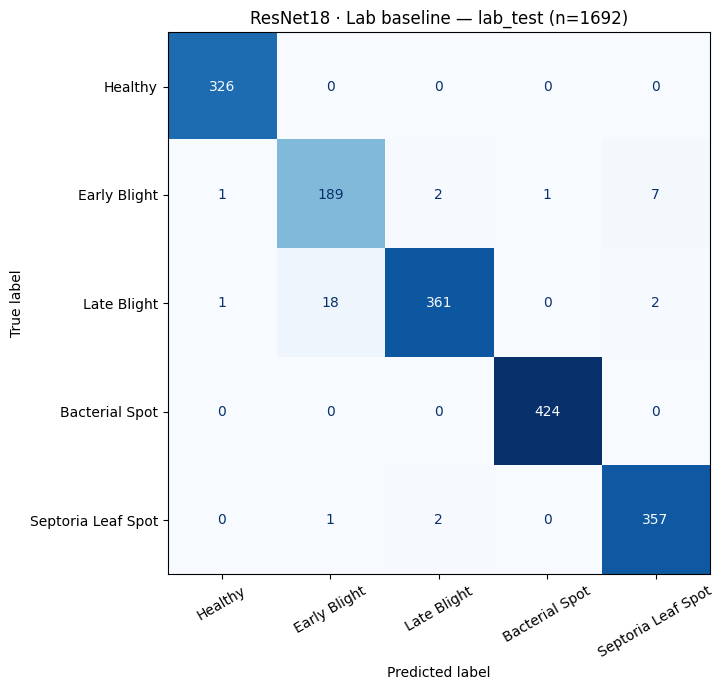

  lab_test: Accuracy=0.9793 | Macro-F1=0.9744 | Correct=1657/1692


README.md:   0%|          | 0.00/542 [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  476MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  516MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2578 [00:00<?, ? examples/s]

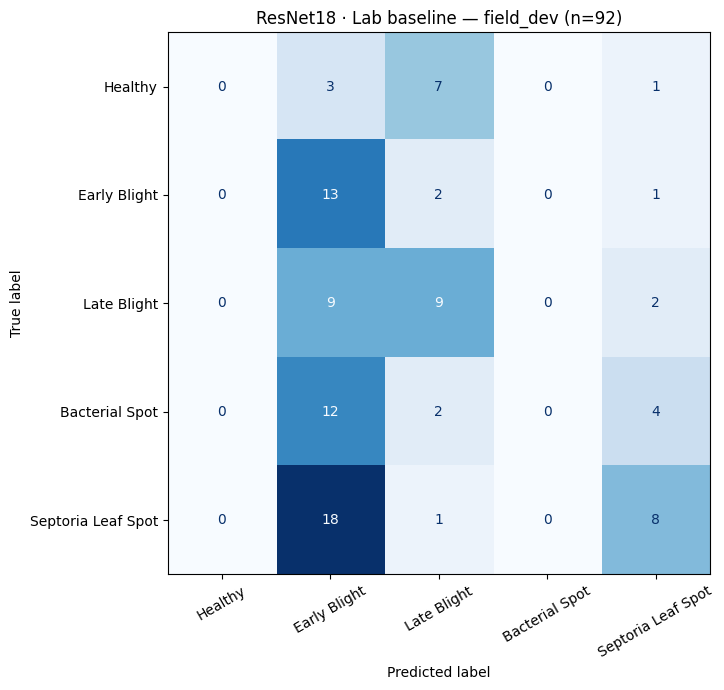

  field_dev: Accuracy=0.3261 | Macro-F1=0.2355 | Correct=30/92

Evaluating: ViT-Small · Lab baseline


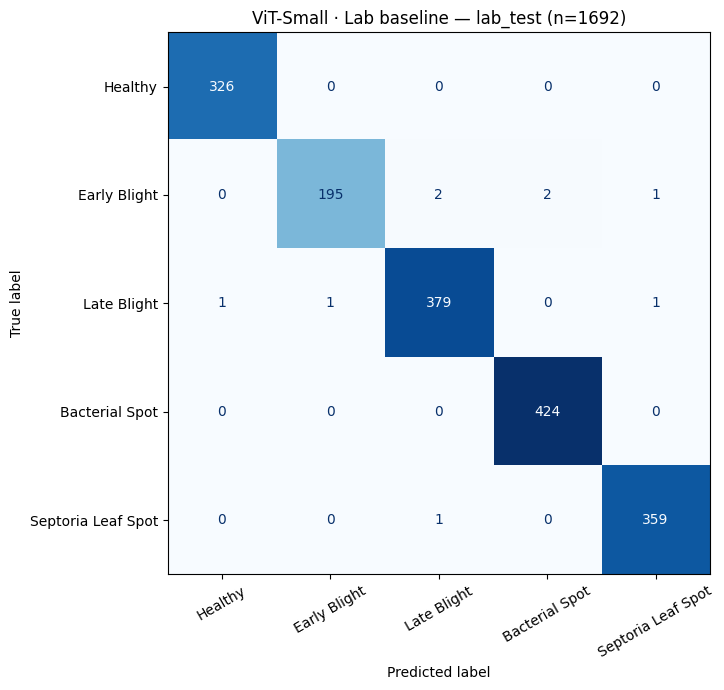

  lab_test: Accuracy=0.9947 | Macro-F1=0.9938 | Correct=1683/1692


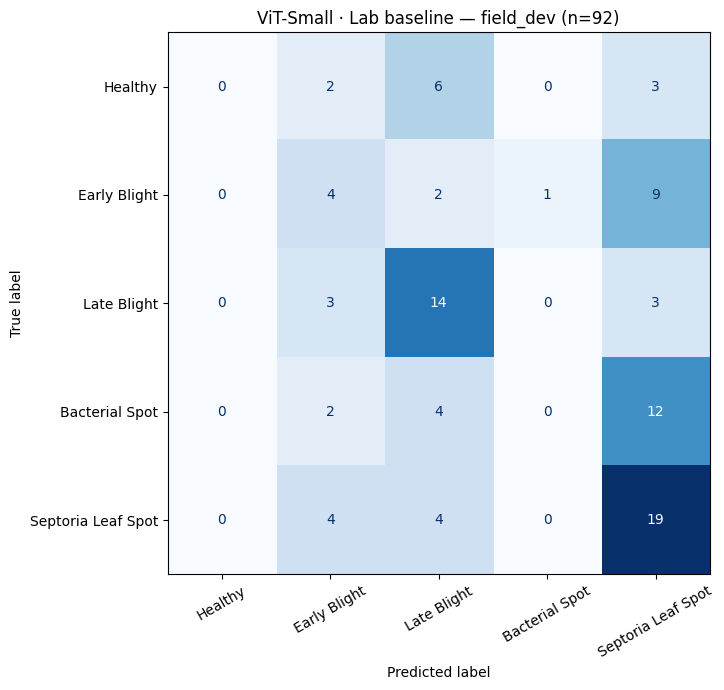

  field_dev: Accuracy=0.4022 | Macro-F1=0.2677 | Correct=37/92

Evaluating: ResNet18 · Geometric + Mixed


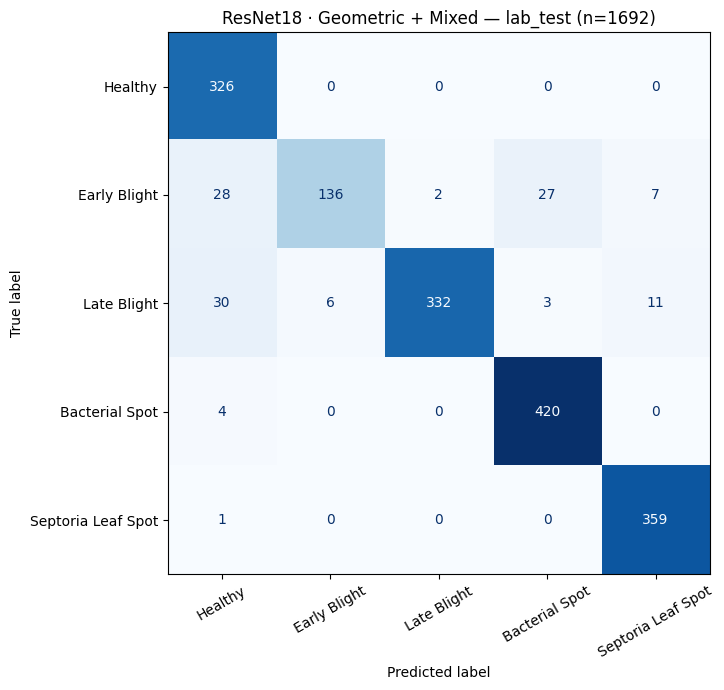

  lab_test: Accuracy=0.9297 | Macro-F1=0.9140 | Correct=1573/1692


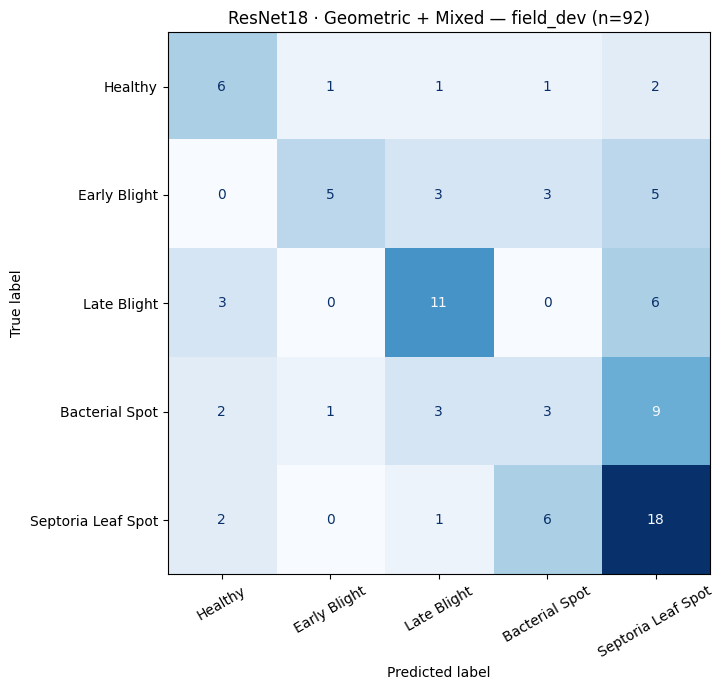

  field_dev: Accuracy=0.4674 | Macro-F1=0.4459 | Correct=43/92

Evaluating: ViT-Small · Mixed


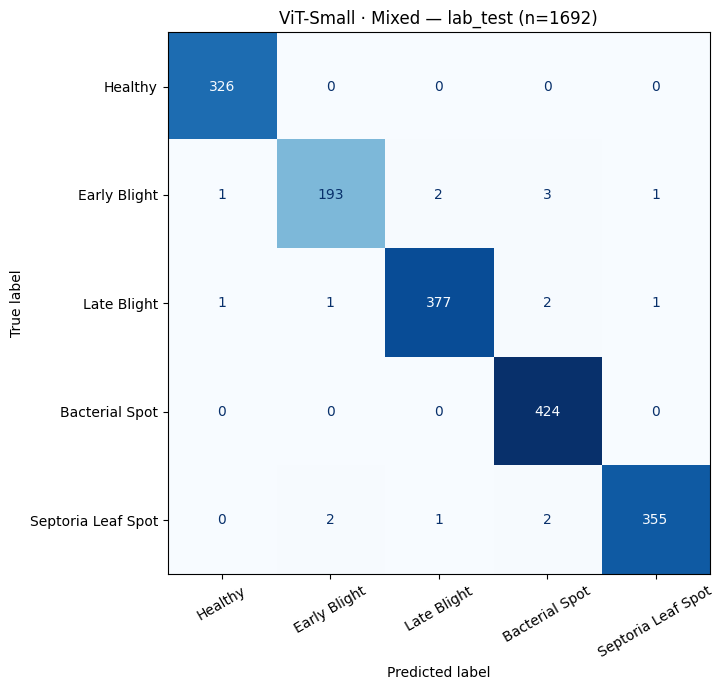

  lab_test: Accuracy=0.9900 | Macro-F1=0.9886 | Correct=1675/1692


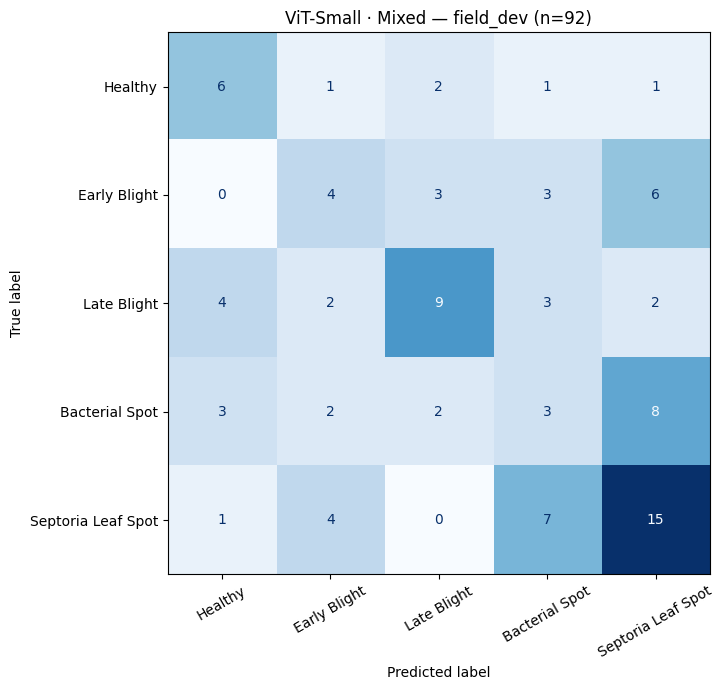

  field_dev: Accuracy=0.4022 | Macro-F1=0.3872 | Correct=37/92


,model,phase,partition,accuracy,macro_f1,correct,images
0,ResNet18 · Lab baseline,lab_only,lab_test,0.9793,0.9744,1657,1692
1,ResNet18 · Lab baseline,lab_only,field_dev,0.3261,0.2355,30,92
2,ViT-Small · Lab baseline,lab_only,lab_test,0.9947,0.9938,1683,1692
3,ViT-Small · Lab baseline,lab_only,field_dev,0.4022,0.2677,37,92
4,ResNet18 · Geometric + Mixed,mixed_domain,lab_test,0.9297,0.9140,1573,1692
5,ResNet18 · Geometric + Mixed,mixed_domain,field_dev,0.4674,0.4459,43,92
6,ViT-Small · Mixed,mixed_domain,lab_test,0.9900,0.9886,1675,1692
7,ViT-Small · Mixed,mixed_domain,field_dev,0.4022,0.3872,37,92


In [6]:
rows = []
per_class_rows = []
prediction_frames = {}

for model_name, spec in CHECKPOINT_SPECS.items():
    print("\nEvaluating:", model_name)
    model, transform = load_fixed_model(model_name)
    model_key = list(CHECKPOINT_SPECS).index(model_name) + 1
    for partition in ("lab_test", "field_dev"):
        dataset = PlantDiseaseDataset(MANIFESTS[partition], transform=transform)
        loader = DataLoader(
            dataset, batch_size=spec["batch_size"], shuffle=False,
            num_workers=0, pin_memory=(DEVICE.type == "cuda"),
        )
        assert dataset.metadata.row_id.tolist() == frames[partition].row_id.tolist()
        observed, predicted, confidence = predict(model, loader)
        assert np.array_equal(observed, frames[partition].label_id.to_numpy())

        score = metrics(observed, predicted)
        rows.append({
            "model": model_name, "phase": spec["phase"], "partition": partition,
            **score,
        })

        report = classification_report(
            observed, predicted, labels=LABEL_IDS, target_names=CLASS_NAMES,
            output_dict=True, zero_division=0,
        )
        for disease in CLASS_NAMES:
            per_class_rows.append({
                "model": model_name, "partition": partition, "class_name": disease,
                "support": int(report[disease]["support"]),
                "precision": float(report[disease]["precision"]),
                "recall": float(report[disease]["recall"]),
                "f1": float(report[disease]["f1-score"]),
            })

        result = frames[partition][["source", "row_id", "class_name", "label_id"]].copy()
        result["predicted_label_id"] = predicted
        result["predicted_class"] = [CLASS_NAMES[int(i)] for i in predicted]
        result["confidence"] = confidence
        result["correct"] = observed == predicted
        result["model"] = model_name
        result["partition"] = partition
        prediction_frames[(model_name, partition)] = result
        result.to_csv(OUTPUT_ROOT / f"predictions_model{model_key}_{partition}.csv", index=False)

        cm = confusion_matrix(observed, predicted, labels=LABEL_IDS)
        fig, ax = plt.subplots(figsize=(9, 7))
        ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
            ax=ax, colorbar=False, cmap="Blues", xticks_rotation=30
        )
        ax.set_title(f"{model_name} — {partition} (n={len(observed)})")
        fig.tight_layout()
        fig.savefig(OUTPUT_ROOT / f"confusion_model{model_key}_{partition}.png", dpi=160)
        plt.show()
        plt.close(fig)
        print(f"  {partition}: Accuracy={score['accuracy']:.4f} | "
              f"Macro-F1={score['macro_f1']:.4f} | Correct={score['correct']}/{score['images']}")
        del dataset, loader
    del model
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

summary = pd.DataFrame(rows)
per_class = pd.DataFrame(per_class_rows)
summary.to_csv(OUTPUT_ROOT / "final_comparison_summary.csv", index=False)
per_class.to_csv(OUTPUT_ROOT / "final_comparison_per_class.csv", index=False)
display(summary.round(4))

## Laboratory performance and descriptive domain gap

The laboratory baselines score Lab Test macro-F1 0.9744 (ResNet18) and 0.9938 (ViT-Small), versus Field Dev 0.2355 and 0.2677. Mixed ResNet18 scores 0.9140 and 0.4459; mixed ViT scores 0.9886 and 0.3872.

The Lab Test minus Field Dev differences describe performance across two differently sampled sources. For adapted models, they also compare laboratory test data with target-domain selection data; they are not independent estimates of adaptation benefit.

,accuracy_field_dev,accuracy_lab_test,macro_f1_field_dev,macro_f1_lab_test,macro_f1_lab_minus_field
model,,,,,
ResNet18 · Lab baseline,0.3261,0.9793,0.2355,0.9744,0.7390
ViT-Small · Lab baseline,0.4022,0.9947,0.2677,0.9938,0.7261
ResNet18 · Geometric + Mixed,0.4674,0.9297,0.4459,0.9140,0.4680
ViT-Small · Mixed,0.4022,0.9900,0.3872,0.9886,0.6015


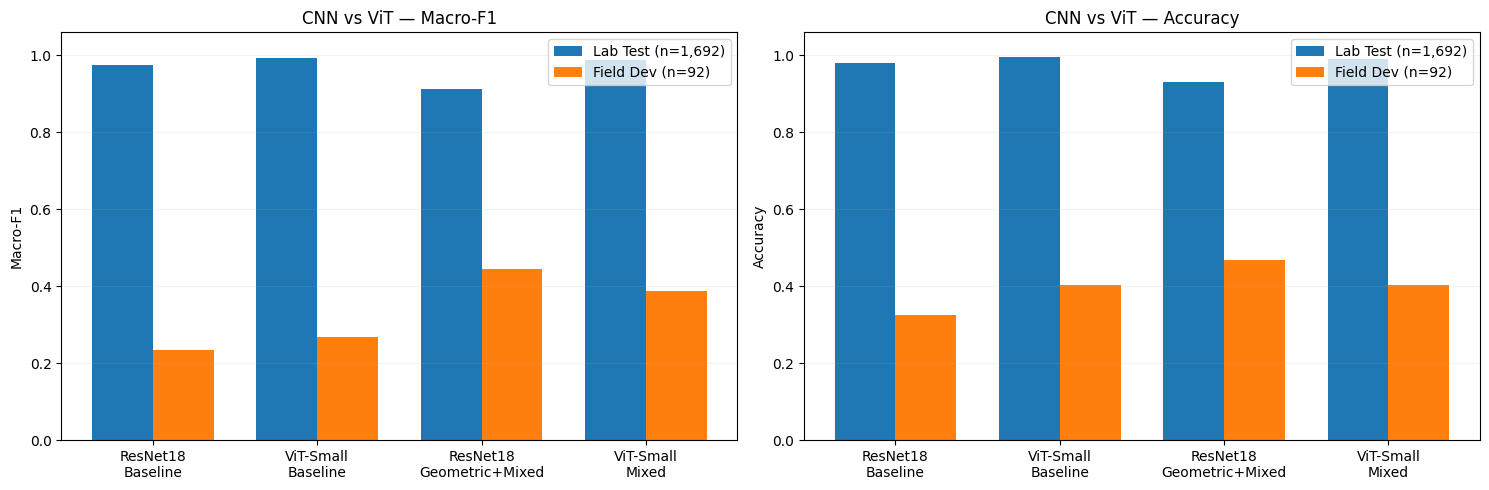

In [7]:
wide = summary.pivot(index="model", columns="partition", values=["accuracy", "macro_f1"])
wide.columns = [f"{metric}_{partition}" for metric, partition in wide.columns]
wide = wide.reindex(CHECKPOINT_SPECS.keys())
wide["macro_f1_lab_minus_field"] = wide["macro_f1_lab_test"] - wide["macro_f1_field_dev"]
wide.to_csv(OUTPUT_ROOT / "lab_field_tradeoff.csv")
display(wide.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
model_labels = ["ResNet18\nBaseline", "ViT-Small\nBaseline",
                "ResNet18\nGeometric+Mixed", "ViT-Small\nMixed"]
x = np.arange(len(model_labels))
bar_width = 0.37
for ax, metric, title in (
    (axes[0], "macro_f1", "Macro-F1"),
    (axes[1], "accuracy", "Accuracy"),
):
    lab = wide[f"{metric}_lab_test"].to_numpy()
    field = wide[f"{metric}_field_dev"].to_numpy()
    ax.bar(x - bar_width/2, lab, width=bar_width, label="Lab Test (n=1,692)")
    ax.bar(x + bar_width/2, field, width=bar_width, label="Field Dev (n=92)")
    ax.set_title(f"CNN vs ViT — {title}")
    ax.set_ylabel(title)
    ax.set_ylim(0, 1.06)
    ax.set_xticks(x, model_labels)
    ax.legend()
    ax.grid(axis="y", alpha=0.15)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "cnn_vs_vit_lab_field.png", dpi=160)
plt.show()
plt.close(fig)

## Class-level recall and paired field errors

Both mixed models recognize 6/11 Healthy and 3/18 Bacterial Spot images. Mixed ResNet18 recognizes 5/16 Early Blight, 11/20 Late Blight, and 18/27 Septoria Leaf Spot; mixed ViT recognizes 4/16, 9/20, and 15/27, respectively.

The models are jointly correct on 24 Field Dev images and jointly wrong on 36. ResNet18 alone is correct on 19 and ViT alone on 13. These paired diagnostics do not establish statistical superiority on an independent field sample.

model,ResNet18 · Lab baseline,ViT-Small · Lab baseline,ResNet18 · Geometric + Mixed,ViT-Small · Mixed
class_name,,,,
Healthy,0.0000,0.0000,0.5455,0.5455
Early Blight,0.8125,0.2500,0.3125,0.2500
Late Blight,0.4500,0.7000,0.5500,0.4500
Bacterial Spot,0.0000,0.0000,0.1667,0.1667
Septoria Leaf Spot,0.2963,0.7037,0.6667,0.5556


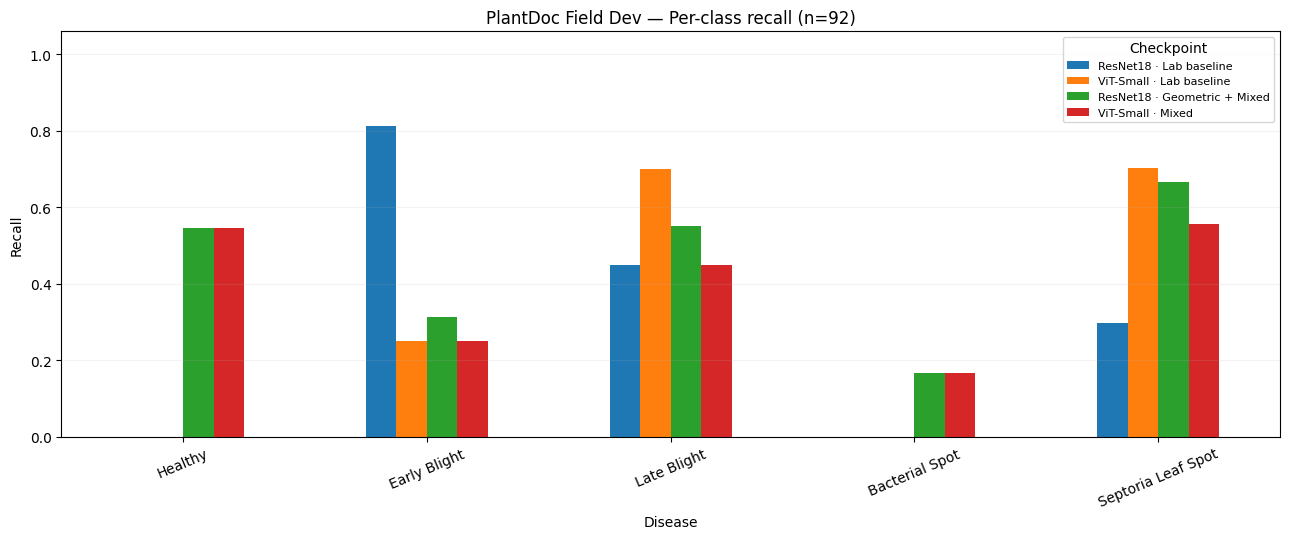

,images
outcome,
both_wrong,36
both_correct,24
resnet_only,19
vit_only,13


In [8]:
field_recall = per_class.loc[per_class.partition == "field_dev"].pivot(
    index="class_name", columns="model", values="recall"
).reindex(index=CLASS_NAMES, columns=CHECKPOINT_SPECS.keys())
display(field_recall.round(4))

fig, ax = plt.subplots(figsize=(13, 5.5))
field_recall.plot(kind="bar", ax=ax, rot=23)
ax.set_title("PlantDoc Field Dev — Per-class recall (n=92)")
ax.set_ylabel("Recall")
ax.set_ylim(0, 1.06)
ax.set_xlabel("Disease")
ax.grid(axis="y", alpha=0.15)
ax.legend(title="Checkpoint", fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "field_dev_per_class_recall.png", dpi=160)
plt.show()
plt.close(fig)

# Pair the two *adapted* model predictions using immutable row_id keys.
a = prediction_frames[("ResNet18 · Geometric + Mixed", "field_dev")]
b = prediction_frames[("ViT-Small · Mixed", "field_dev")]
paired = a[["row_id", "label_id", "class_name", "correct", "predicted_class"]].rename(
    columns={"correct": "resnet_correct", "predicted_class": "resnet_prediction"}
).merge(
    b[["row_id", "label_id", "correct", "predicted_class"]].rename(
        columns={"correct": "vit_correct", "predicted_class": "vit_prediction"}
    ), on=["row_id", "label_id"], how="inner", validate="one_to_one"
)
assert len(paired) == len(frames["field_dev"])
paired["outcome"] = np.select(
    [paired.resnet_correct & paired.vit_correct,
     paired.resnet_correct & ~paired.vit_correct,
     ~paired.resnet_correct & paired.vit_correct],
    ["both_correct", "resnet_only", "vit_only"], default="both_wrong"
)
paired.to_csv(OUTPUT_ROOT / "adapted_models_paired_field_dev.csv", index=False)
display(paired["outcome"].value_counts().rename("images").to_frame())

## Evaluation provenance record

The exported record includes source commit, device, framework versions, manifest and checkpoint hashes, partition counts, and Field Dev selection caveats. Predictions and summary CSVs are saved under the Drive `final_comparison_development/` directory. These external artifacts are not included in the repository.

In [9]:
record = {
    "research_task": "Fine-grained tomato leaf disease diagnosis: CNN vs ViT, Lab-to-Field",
    "git_commit": GIT_SHA,
    "device": str(DEVICE),
    "framework_versions": {"torch": torch.__version__, "timm": timm.__version__},
    "class_names": CLASS_NAMES,
    "manifests_sha256": MANIFEST_HASHES,
    "checkpoints_sha256": {
        name: sha256_file(spec["checkpoint"])
        for name, spec in CHECKPOINT_SPECS.items()
    },
    "evaluation_partitions": {"lab_test": 1692, "field_dev": 92},
    "field_test_inference_performed": False,
    "model_selection_note": "Mixed models were selected on Field Dev; results are developmental, not independent test results.",
    "independent_field_test_note": "The original 47-image Field Test was previously inspected and is not used as a fresh independent holdout.",
    "next_validation": "Collect or designate new independent field images and audit near duplicates and labels before confirmatory evaluation.",
}
(OUTPUT_ROOT / "comparison_protocol.json").write_text(
    json.dumps(record, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Saved to:", OUTPUT_ROOT)
print("Files:")
for p in sorted(OUTPUT_ROOT.iterdir()):
    if p.is_file():
        print(" -", p.name)

Saved to: /content/drive/MyDrive/plant-disease-diagnosis/final_comparison_development
Files:
 - adapted_models_paired_field_dev.csv
 - cnn_vs_vit_lab_field.png
 - comparison_protocol.json
 - confusion_model1_field_dev.png
 - confusion_model1_lab_test.png
 - confusion_model2_field_dev.png
 - confusion_model2_lab_test.png
 - confusion_model3_field_dev.png
 - confusion_model3_lab_test.png
 - confusion_model4_field_dev.png
 - confusion_model4_lab_test.png
 - field_dev_per_class_recall.png
 - final_comparison_per_class.csv
 - final_comparison_summary.csv
 - lab_field_tradeoff.csv
 - predictions_model1_field_dev.csv
 - predictions_model1_lab_test.csv
 - predictions_model2_field_dev.csv
 - predictions_model2_lab_test.csv
 - predictions_model3_field_dev.csv
 - predictions_model3_lab_test.csv
 - predictions_model4_field_dev.csv
 - predictions_model4_lab_test.csv


## Results and interpretation

Among laboratory baselines, ViT has higher Lab Test macro-F1 (0.9938 versus 0.9744), but both score much lower on Field Dev. Mixed ResNet18 achieves the highest Field Dev macro-F1 of the four fixed models (0.4459; 43/92 correct), while mixed ViT retains higher Lab Test macro-F1 (0.9886 versus 0.9140) and scores 0.3872 on Field Dev (37/92 correct).

Mixed ViT and its laboratory baseline have the same Field Dev accuracy (0.4022), despite different macro-F1, reflecting changed class-level errors. The ResNet18 baseline-to-mixed contrast includes both geometric initialization and mixed fine-tuning; notebook 08 provides the corresponding initialization-matched controls.

The recorded experiments cover laboratory comparison, domain shift, augmentation, and supervised adaptation. These observations do not establish general CNN/transformer superiority: configurations differ in pretraining, capacity, preprocessing, and optimization. Field Dev was used for selection, and an independent field test is absent. Quantization and mobile deployment were not performed.